# Lab 04 — Character-Level Language Model with RNN (and LSTM)

**Goal:** train a model that reads 40 characters and predicts the 41st, then use it to write new text in the style of the training data.

**Dataset:** the first 80 of Shakespeare's Sonnets (public domain, Project Gutenberg), trimmed to **under 50 KB** → `data/sonnets.txt`.

| Task | Section |
|---|---|
| 1. Load text, build char↔index mappings | §1 |
| 2. 40-char input sequences → predict 41st, vectorize | §2 |
| 3. Create training sequences (train / validation) | §3 |
| 4. Build the SimpleRNN model | §4 |
| 5. Train the model | §5 |
| 6. Text generation function | §6 |
| 7. Generate new text and validate | §7 |

**Extra learning components:** n-gram baselines (§8), an **LSTM** model with a head-to-head comparison against the SimpleRNN (§9), a temperature sweep (§10), a look inside the model's next-character probabilities (§11), and saving/reloading the trained model (§12).

In [1]:
import os
import re
import math
from collections import Counter

import numpy as np
import matplotlib.pyplot as plt
import tensorflow as tf
from tensorflow import keras

keras.utils.set_random_seed(42)  # same weights, shuffles and samples on every run
print('TensorFlow', tf.__version__)

TensorFlow 2.21.0


## 1. Load text and build character mappings

A character-level model's "vocabulary" is just the set of distinct characters. Each character gets an integer ID (`char2idx`) and we keep the reverse lookup (`idx2char`) to turn predictions back into text.

The text is **lowercased**: this shrinks the vocabulary (no separate `T`/`t`), so the model has fewer classes to learn from a small file.

In [2]:
DATA_PATH = 'data/sonnets.txt'

size_kb = os.path.getsize(DATA_PATH) / 1024
assert size_kb <= 50, 'Input must be a small file (<= 50 KB)'

with open(DATA_PATH, encoding='utf-8') as f:
    text = f.read().lower()

vocab = sorted(set(text))
char2idx = {c: i for i, c in enumerate(vocab)}
idx2char = np.array(vocab)
VOCAB_SIZE = len(vocab)

print(f'File size      : {size_kb:.1f} KB')
print(f'Characters     : {len(text):,}')
print(f'Vocabulary size: {VOCAB_SIZE}')
print('Vocabulary     :', repr(''.join(vocab)))
print('\nFirst 300 characters:\n')
print(text[:300])

File size      : 47.8 KB
Characters     : 48,900
Vocabulary size: 36
Vocabulary     : "\n !',-.:;?abcdefghijklmnopqrstuvwxyz"

First 300 characters:

from fairest creatures we desire increase,
that thereby beauty's rose might never die,
but as the riper should by time decease,
his tender heir might bear his memory:
but thou, contracted to thine own bright eyes,
feed'st thy light's flame with self-substantial fuel,
making a famine where abundance 


In [3]:
# char -> index table (first 15 entries)
for c in vocab[:15]:
    print(f'{c!r:6} -> {char2idx[c]}')

# self-check: encoding then decoding gives back the original text
sample = text[:100]
encoded = [char2idx[c] for c in sample]
assert ''.join(idx2char[encoded]) == sample
print('\nEncoded sample :', encoded[:20], '...')
print('Round-trip OK')

'\n'   -> 0
' '    -> 1
'!'    -> 2
"'"    -> 3
','    -> 4
'-'    -> 5
'.'    -> 6
':'    -> 7
';'    -> 8
'?'    -> 9
'a'    -> 10
'b'    -> 11
'c'    -> 12
'd'    -> 13
'e'    -> 14

Encoded sample : [15, 27, 24, 22, 1, 15, 10, 18, 27, 14, 28, 29, 1, 12, 27, 14, 10, 29, 30, 27] ...
Round-trip OK


## 2. Vectorize the text and cut it into 40-character sequences

*Vectorizing* = replacing every character by its integer ID, so the whole text becomes one long integer array.

We then slide a window over that array. Each window holds **40 characters (input)** and the **41st character is the label**:

```
text  :  f r o m _ f a i r e s t _ c r e a t u r e s ...
input :  [f r o m _ ... (40 chars) ...]
label :                                  next char (41st)
```

`STEP = 3` moves the window 3 characters at a time. Step 1 would give 3× more (but highly overlapping) samples and 3× slower epochs.

In [4]:
SEQ_LEN = 40
STEP = 3

encoded_text = np.array([char2idx[c] for c in text], dtype=np.int32)

X_all, y_all = [], []
for i in range(0, len(encoded_text) - SEQ_LEN, STEP):
    X_all.append(encoded_text[i:i + SEQ_LEN])
    y_all.append(encoded_text[i + SEQ_LEN])
X_all = np.array(X_all)
y_all = np.array(y_all)

print('X shape:', X_all.shape, '  (sequences, 40 chars)')
print('y shape:', y_all.shape, '  (one next-char label per sequence)')

# self-check: the label really is the character right after the window
assert X_all.shape[1] == SEQ_LEN
assert (X_all[1] == encoded_text[STEP:STEP + SEQ_LEN]).all()
assert y_all[1] == encoded_text[STEP + SEQ_LEN]

for k in range(3):
    print(f'\ninput : {"".join(idx2char[X_all[k]])!r}')
    print(f'target: {idx2char[y_all[k]]!r}')

X shape: (16287, 40)   (sequences, 40 chars)
y shape: (16287,)   (one next-char label per sequence)

input : 'from fairest creatures we desire increas'
target: np.str_('e')

input : 'm fairest creatures we desire increase,\n'
target: np.str_('t')

input : 'airest creatures we desire increase,\ntha'
target: np.str_('t')


### What a "vector" for one character looks like

Inside the network the IDs are turned into vectors. The classic way is **one-hot encoding** (a vector of zeros with a single 1). Our model uses an **Embedding** layer instead, which is a *learned* dense vector per character — mathematically the same as one-hot × weight matrix, but cheaper.

In [5]:
c = text[0]
one_hot = np.eye(VOCAB_SIZE, dtype=int)[char2idx[c]]
print(f'{c!r} -> id {char2idx[c]} -> one-hot {one_hot}')

'f' -> id 15 -> one-hot [0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 1 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0]


## 3. Create the training sequences (train / validation split)

We hold out the **last 10% of the text** for validation instead of picking random windows.

Why? Neighbouring windows overlap by 37 of their 40 characters. A random split would put almost-identical windows in both sets, and the validation score would look better than it really is (data leakage). A contiguous split keeps validation text truly unseen.

In [6]:
split = int(len(X_all) * 0.9)
X_train, y_train = X_all[:split], y_all[:split]
X_val,   y_val   = X_all[split:], y_all[split:]

print(f'Train sequences     : {len(X_train):,}')
print(f'Validation sequences: {len(X_val):,}')

Train sequences     : 14,658
Validation sequences: 1,629


## 4. Build the RNN model

Architecture (the two `SimpleRNN` layers are exactly those from the task):

| Layer | Output shape | Role |
|---|---|---|
| `Embedding(VOCAB, 64)` | (40, 64) | char ID → learned 64-d vector |
| `SimpleRNN(256, return_sequences=True)` | (40, 256) | reads the sequence, outputs a hidden state **at every step** so the next RNN layer gets a sequence |
| `SimpleRNN(256)` | (256,) | second RNN layer, outputs only the **last** hidden state (a summary of all 40 chars) |
| `Dropout(0.2)` | (256,) | regularisation against overfitting a small text |
| `Dense(VOCAB, softmax)` | (VOCAB,) | probability for every possible next character |

`clipnorm=1.0` in the optimizer caps the gradient size — RNNs are prone to *exploding gradients* because the same weights are multiplied again at every time step.

In [7]:
def build_model(rnn_layer, name):
    """Embedding -> 2 stacked recurrent layers -> softmax over the vocabulary."""
    model = keras.Sequential([
        keras.Input(shape=(SEQ_LEN,)),
        keras.layers.Embedding(VOCAB_SIZE, 64),
        rnn_layer(256, return_sequences=True),
        rnn_layer(256),
        keras.layers.Dropout(0.2),
        keras.layers.Dense(VOCAB_SIZE, activation='softmax'),
    ], name=name)
    model.compile(
        optimizer=keras.optimizers.Adam(learning_rate=2e-3, clipnorm=1.0),
        loss='sparse_categorical_crossentropy',  # labels are integer IDs, not one-hot
        metrics=['accuracy'],
    )
    return model

rnn_model = build_model(keras.layers.SimpleRNN, 'simple_rnn')
rnn_model.summary()

Model: "simple_rnn"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ embedding (Embedding)           │ (None, 40, 64)         │         2,304 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ simple_rnn (SimpleRNN)          │ (None, 40, 256)        │        82,176 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ simple_rnn_1 (SimpleRNN)        │ (None, 256)            │       131,328 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 256)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 36)             │         9,252 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 225,060 (879.14 KB)

 Trainable params: 225,060 (879.14 KB)

 Non-trainable params: 0 (0.00 B)

## 5. Train the model

* **EarlyStopping** watches validation loss, stops when it hasn't improved for 4 epochs, and restores the best weights — so we keep the model from *before* it started memorising the training text.
* **ReduceLROnPlateau** halves the learning rate when progress stalls, letting the model settle into a better minimum.

In [8]:
EPOCHS = 40
BATCH = 128

def callbacks():
    return [
        keras.callbacks.EarlyStopping(monitor='val_loss', patience=4, restore_best_weights=True),
        keras.callbacks.ReduceLROnPlateau(monitor='val_loss', factor=0.5, patience=2, min_lr=1e-4),
    ]

rnn_history = rnn_model.fit(
    X_train, y_train,
    validation_data=(X_val, y_val),
    epochs=EPOCHS, batch_size=BATCH,
    callbacks=callbacks(), verbose=2,
)

Epoch 1/40


115/115 - 9s - 81ms/step - accuracy: 0.1092 - loss: 3.2682 - val_accuracy: 0.1633 - val_loss: 3.0496 - learning_rate: 0.0020


Epoch 2/40


115/115 - 6s - 55ms/step - accuracy: 0.1195 - loss: 3.1924 - val_accuracy: 0.1633 - val_loss: 3.0239 - learning_rate: 0.0020


Epoch 3/40


115/115 - 7s - 57ms/step - accuracy: 0.1740 - loss: 3.0224 - val_accuracy: 0.2167 - val_loss: 2.9352 - learning_rate: 0.0020


... (42 outputs left out)

Epoch 25/40


115/115 - 6s - 51ms/step - accuracy: 0.5810 - loss: 1.3558 - val_accuracy: 0.4273 - val_loss: 1.9821 - learning_rate: 5.0000e-04


Epoch 26/40


115/115 - 6s - 51ms/step - accuracy: 0.5900 - loss: 1.3248 - val_accuracy: 0.4371 - val_loss: 1.9835 - learning_rate: 5.0000e-04


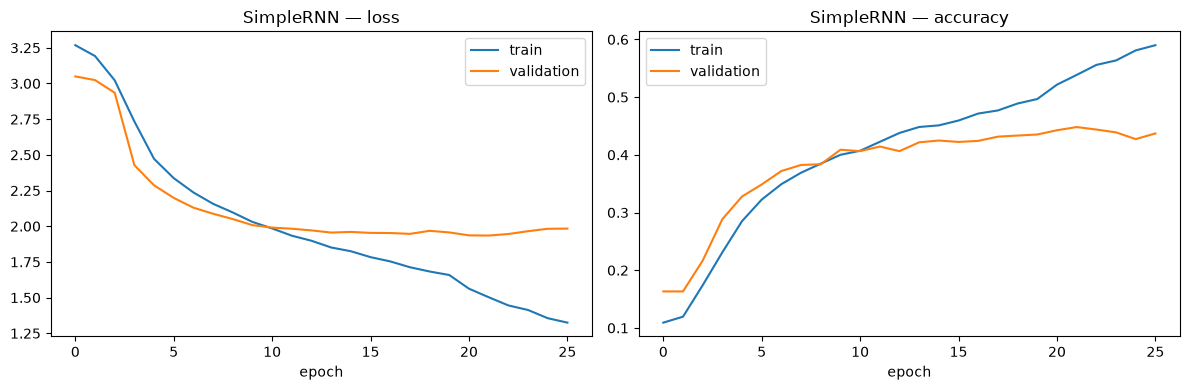

In [9]:
def plot_history(history, title):
    h = history.history
    fig, (a1, a2) = plt.subplots(1, 2, figsize=(12, 4))
    a1.plot(h['loss'], label='train'); a1.plot(h['val_loss'], label='validation')
    a1.set_title(f'{title} — loss'); a1.set_xlabel('epoch'); a1.legend()
    a2.plot(h['accuracy'], label='train'); a2.plot(h['val_accuracy'], label='validation')
    a2.set_title(f'{title} — accuracy'); a2.set_xlabel('epoch'); a2.legend()
    plt.tight_layout(); plt.show()

plot_history(rnn_history, 'SimpleRNN')

## 6. Text generation function

Generation is a loop:

1. Take the last 40 characters of the text so far.
2. Ask the model for the probability of each next character.
3. **Sample** one character from that distribution (not just the most likely one — always picking the max quickly loops into repeated phrases).
4. Append it and repeat.

**Temperature** reshapes the distribution before sampling: `p_i ∝ exp(log p_i / T)`.
* `T < 1` → sharper: safer, more repetitive text.
* `T = 1` → the model's own distribution.
* `T > 1` → flatter: more creative, more spelling mistakes.

In [10]:
def sample_index(probs, temperature=1.0):
    """Pick a character index from a probability vector, reshaped by temperature."""
    probs = np.asarray(probs, dtype=np.float64)
    logits = np.log(probs + 1e-10) / temperature
    probs = np.exp(logits - logits.max())
    probs /= probs.sum()
    return np.random.choice(len(probs), p=probs)


def generate_text(model, seed, length=400, temperature=0.7):
    """Continue `seed` with `length` new characters sampled from `model`."""
    seed = ''.join(c for c in seed.lower() if c in char2idx)  # drop chars the model never saw
    assert seed, 'seed has no known characters'
    ids = [char2idx[c] for c in seed]
    for _ in range(length):
        window = ids[-SEQ_LEN:]
        window = [char2idx[' ']] * (SEQ_LEN - len(window)) + window  # left-pad short seeds
        probs = model(np.array([window]), training=False).numpy()[0]
        ids.append(sample_index(probs, temperature))
    return ''.join(idx2char[ids])

## 7. Generate new text and validate it

### 7a. Generated samples

In [11]:
SEED = 'shall i compare thee to a summer\'s day?\n'

rnn_sample = generate_text(rnn_model, SEED, length=500, temperature=0.6)
print(rnn_sample)

shall i compare thee to a summer's day?
hoth farth when i former the bearts por ard in their stren
i dome as wom the beauty she the sours colder of i eeturs, thou art the ginker on my deartes dive thou is the stare,
thou art the herst thou hading seef thou mend,
stire,
the head,
with thou befient, and sume of thus thou be,
and seath the beauty, and carse of the world till as me the spare the sarth then the bair frate thou beauty thou me thou day it not ereries of me the sarte when whe soor of eecuinted araze tree,
the oud with my love


### 7b. Validation

"Looks like Shakespeare" is subjective, so we also measure it:

**On held-out text (how well the model predicts):**
* **Validation loss / accuracy** — cross-entropy and next-char hit rate on the unseen 10%.
* **Perplexity** = `exp(loss)` — "the model is as unsure as if it were choosing uniformly among *N* characters". Lower is better; guessing at random gives `VOCAB_SIZE`.

**On generated text (how much it resembles the style):**
* **Real-word rate** — share of generated words that also appear in the training text.
* **Character-distribution distance** — total variation distance between character frequencies of generated vs training text (0 = identical, 1 = disjoint).
* **Average line length** — sonnet lines are ~40 characters; a model that learned the form should produce similar line breaks.
* **Copied 20-grams** — share of generated 20-character chunks found verbatim in the training text. High = memorising, low = creating new text.

In [12]:
train_words = set(re.findall(r"[a-z']+", text))
train_freq = Counter(text)
train_20grams = {text[i:i + 20] for i in range(len(text) - 19)}
train_line_len = np.mean([len(l) for l in text.split('\n') if l.strip()])


def eval_model(model):
    loss, acc = model.evaluate(X_val, y_val, verbose=0)
    return {'val_loss': loss, 'val_acc': acc, 'perplexity': math.exp(loss)}


def style_metrics(generated):
    words = re.findall(r"[a-z']+", generated)
    gen_freq = Counter(generated)
    n_gen, n_train = len(generated), len(text)
    tvd = 0.5 * sum(abs(gen_freq[c] / n_gen - train_freq[c] / n_train) for c in vocab)
    lines = [l for l in generated.split('\n') if l.strip()]
    grams = [generated[i:i + 20] for i in range(len(generated) - 19)]
    return {
        'real_word_rate': sum(w in train_words for w in words) / max(len(words), 1),
        'char_dist_distance': tvd,
        'avg_line_len': float(np.mean([len(l) for l in lines])) if lines else 0.0,
        'copied_20grams': sum(g in train_20grams for g in grams) / max(len(grams), 1),
    }


# sanity check: the training text itself should score as perfectly "in style"
self_check = style_metrics(text[:text.find('\n\n')])  # first full sonnet
assert self_check['real_word_rate'] == 1.0 and self_check['copied_20grams'] == 1.0

rnn_scores = eval_model(rnn_model)
rnn_style = style_metrics(rnn_sample[len(SEED):])  # score only the generated part

print(f'Uniform-guess perplexity : {VOCAB_SIZE}')
for k, v in {**rnn_scores, **rnn_style}.items():
    print(f'{k:20}: {v:.3f}')
print(f'{"(training avg line len)":20}: {train_line_len:.3f}')

Uniform-guess perplexity : 36
val_loss            : 1.935
val_acc             : 0.448
perplexity          : 6.923
real_word_rate      : 0.660
char_dist_distance  : 0.147
avg_line_len        : 61.625
copied_20grams      : 0.000
(training avg line len): 42.590


## 8. Extra — How good is that? N-gram baselines

A perplexity number means little on its own. We compare against two models with **no neural network**:

* **Unigram:** always predict the overall character frequencies (knows `e` and space are common, nothing else).
* **Bigram:** predict from the *previous character only* (knows `q` is followed by `u`), with add-one smoothing.

The RNN sees 40 characters of context, so it should beat both clearly. If it didn't, the network would not be learning anything beyond simple counts.

In [13]:
train_ids = encoded_text[: split * STEP + SEQ_LEN]   # text covered by training windows
val_prev, val_next = X_val[:, -1], y_val              # previous char and true next char

uni = np.bincount(train_ids, minlength=VOCAB_SIZE) + 1
uni = uni / uni.sum()

bi = np.ones((VOCAB_SIZE, VOCAB_SIZE))
np.add.at(bi, (train_ids[:-1], train_ids[1:]), 1)
bi = bi / bi.sum(axis=1, keepdims=True)

baseline_ppl = {
    'uniform guess': VOCAB_SIZE,
    'unigram': math.exp(-np.mean(np.log(uni[val_next]))),
    'bigram': math.exp(-np.mean(np.log(bi[val_prev, val_next]))),
    'SimpleRNN': rnn_scores['perplexity'],
}
for k, v in baseline_ppl.items():
    print(f'{k:14} perplexity: {v:6.2f}')

uniform guess  perplexity:  36.00
unigram        perplexity:  19.83
bigram         perplexity:  10.58
SimpleRNN      perplexity:   6.92


## 9. Extra — LSTM model

A `SimpleRNN` updates its hidden state as `h_t = tanh(W·x_t + U·h_{t-1} + b)`. During training the gradient passes back through that same `U` and `tanh` at every step, so it tends to **shrink towards zero (vanishing gradient)** — the model struggles to use characters far back in the window.

An **LSTM** adds a separate *cell state* `c_t` plus three gates:
* **forget gate** – what to erase from memory,
* **input gate** – what new information to store,
* **output gate** – what part of memory to expose as `h_t`.

The cell state is updated by *addition* (`c_t = f·c_{t-1} + i·g`), which lets gradients flow over many steps. Same pipeline, same hyper-parameters — only the recurrent layer changes.

Model: "lstm"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ embedding_1 (Embedding)         │ (None, 40, 64)         │         2,304 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lstm (LSTM)                     │ (None, 40, 256)        │       328,704 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lstm_1 (LSTM)                   │ (None, 256)            │       525,312 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 256)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 36)             │         9,252 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 865,572 (3.30 MB)

 Trainable params: 865,572 (3.30 MB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/40


... (17 outputs left out)

Epoch 10/40


115/115 - 27s - 238ms/step - accuracy: 0.5772 - loss: 1.3494 - val_accuracy: 0.4518 - val_loss: 1.9030 - learning_rate: 0.0010


Epoch 11/40


115/115 - 26s - 227ms/step - accuracy: 0.6115 - loss: 1.2419 - val_accuracy: 0.4610 - val_loss: 1.9152 - learning_rate: 0.0010


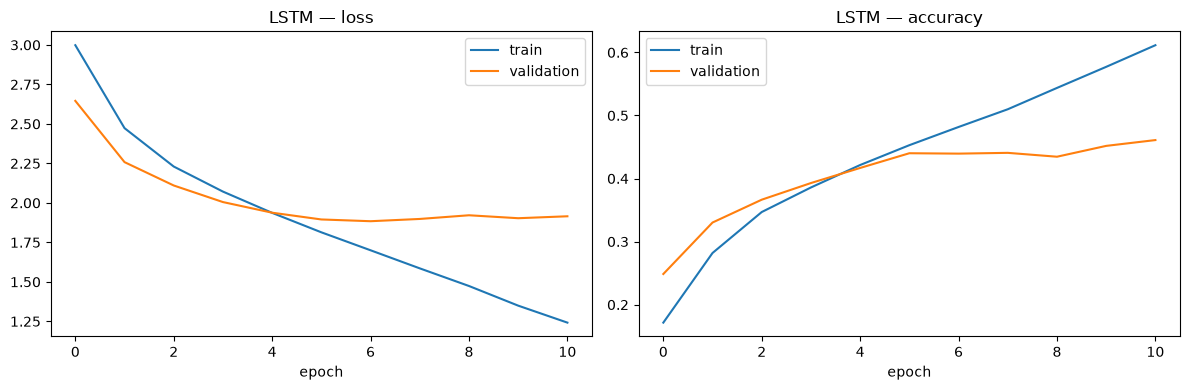

In [14]:
lstm_model = build_model(keras.layers.LSTM, 'lstm')
lstm_model.summary()

lstm_history = lstm_model.fit(
    X_train, y_train,
    validation_data=(X_val, y_val),
    epochs=EPOCHS, batch_size=BATCH,
    callbacks=callbacks(), verbose=2,
)
plot_history(lstm_history, 'LSTM')

In [15]:
lstm_sample = generate_text(lstm_model, SEED, length=500, temperature=0.6)
print(lstm_sample)

shall i compare thee to a summer's day?
the thought than to show lot thyself deave the skowth the torld my love offrard not plad,
and the dead
all mord,
and in if of my fours more and dorth borsed ind whe decild,
of erow desors, and i offare me whongh storlld what thine the with thine more whe thee beaust thing lood spome,
when dist the world to may but shall more my epceart rich whe with my dart the meartur shall all ade that the depain eutire,
show i wolld that shast do thing, ace thee when do make the streeld of that shange pomperi


In [16]:
lstm_scores = eval_model(lstm_model)
lstm_style = style_metrics(lstm_sample[len(SEED):])
baseline_ppl['LSTM'] = lstm_scores['perplexity']

rows = [
    ('parameters', rnn_model.count_params(), lstm_model.count_params()),
    ('epochs trained', len(rnn_history.history['loss']), len(lstm_history.history['loss'])),
    *[(k, rnn_scores[k], lstm_scores[k]) for k in rnn_scores],
    *[(k, rnn_style[k], lstm_style[k]) for k in rnn_style],
]
print(f'{"metric":20}{"SimpleRNN":>12}{"LSTM":>12}')
for name, a, b in rows:
    print(f'{name:20}{a:12.3f}{b:12.3f}' if isinstance(a, float) else f'{name:20}{a:12,}{b:12,}')

metric                 SimpleRNN        LSTM
parameters               225,060     865,572
epochs trained                26          11
val_loss                   1.935       1.884
val_acc                    0.448       0.440
perplexity                 6.923       6.579
real_word_rate             0.660       0.636
char_dist_distance         0.147       0.131
avg_line_len              61.625      70.571
copied_20grams             0.000       0.000


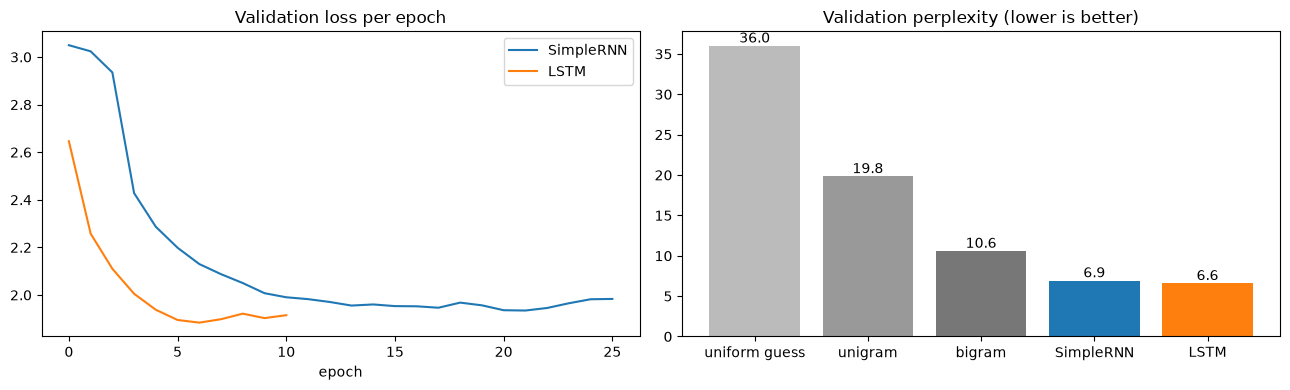

In [17]:
fig, (a1, a2) = plt.subplots(1, 2, figsize=(13, 4))
a1.plot(rnn_history.history['val_loss'], label='SimpleRNN')
a1.plot(lstm_history.history['val_loss'], label='LSTM')
a1.set_title('Validation loss per epoch'); a1.set_xlabel('epoch'); a1.legend()

names, vals = zip(*baseline_ppl.items())
a2.bar(names, vals, color=['#bbb', '#999', '#777', '#1f77b4', '#ff7f0e'])
a2.set_title('Validation perplexity (lower is better)')
for i, v in enumerate(vals):
    a2.text(i, v, f'{v:.1f}', ha='center', va='bottom')
plt.tight_layout(); plt.show()

## 10. Extra — Temperature sweep

Same model (the better of the two by validation loss), same seed, different temperatures. Watch the trade-off between *safe but repetitive* and *creative but misspelled*, and see it in the real-word rate.

In [18]:
best_model = lstm_model if lstm_scores['val_loss'] < rnn_scores['val_loss'] else rnn_model
print('Using:', best_model.name, '\n')

for T in [0.2, 0.5, 1.0, 1.5]:
    out = generate_text(best_model, SEED, length=250, temperature=T)[len(SEED):]
    m = style_metrics(out)
    print(f'=== temperature {T}  |  real words {m["real_word_rate"]:.0%}  |  copied 20-grams {m["copied_20grams"]:.0%} ===')
    print(out, '\n')

Using: lstm 



=== temperature 0.2  |  real words 93%  |  copied 20-grams 0% ===
the with thou when i love the dead
the dead the with the so some the dead
when the world the with the world the dead
the world the with the with the world the dead,
the defping the should the show when i morst the the thou whould the with the world t 



=== temperature 0.5  |  real words 72%  |  copied 20-grams 0% ===
the with thou art the welld do shall made
some bot when thee whought blave,
and then thine own more the mord still from whought more,
the with thou should of sull doth not all ase more and to thou world sellf showet whould misting boch not for the mo 



=== temperature 1.0  |  real words 37%  |  copied 20-grams 0% ===
oid in opnest
canter what for grome do moer whot puntse's to frith brind,
be the indward stweeth bered.
and eow me swonkecive,
niph tord duth no partibf have love;
yout thou that retrolls on mid,
afurt hio peish thav sweej buchtord no that tho hicht  



=== temperature 1.5  |  real words 24%  |  copied 20-grams 0% ===
ni fwowide the griingsttoln evay optnn
ngore brac'tile to dens.

whou, and mays yoursh gudf.
ovad uperutt! lotkienyr dbow my more, uos lafsy
is murbers
sarbxgh gty love ko
nit off:
opgordinc growim glaesty? jove thir he ase guemut's ldass, thich weak 



## 11. Extra — What is the model thinking?

For a few prompts we print the model's **top-5 next-character guesses** with their probabilities. This shows what the network has learned about spelling, word endings and punctuation.

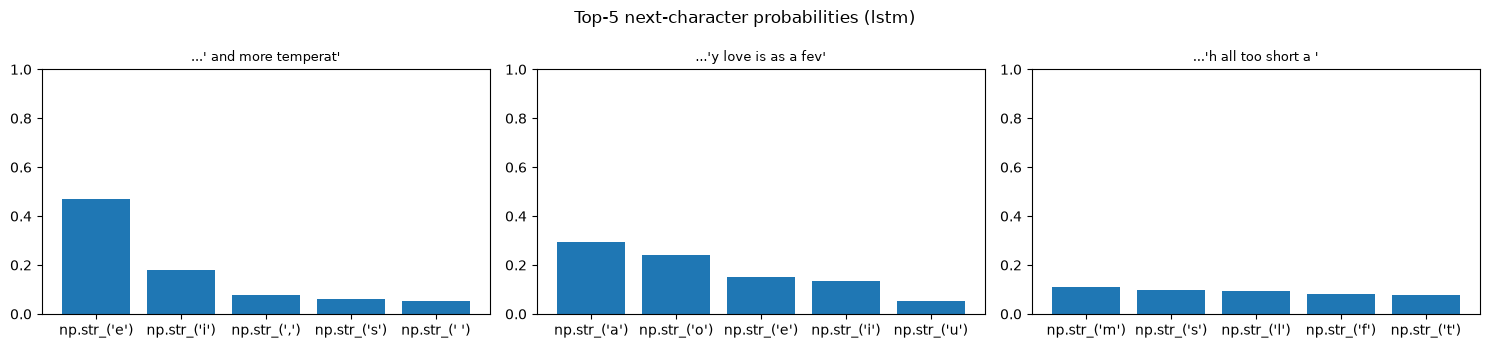

In [19]:
def top_k_next(model, prompt, k=5):
    ids = [char2idx[c] for c in prompt.lower() if c in char2idx][-SEQ_LEN:]
    ids = [char2idx[' ']] * (SEQ_LEN - len(ids)) + ids
    probs = model(np.array([ids]), training=False).numpy()[0]
    top = probs.argsort()[::-1][:k]
    return [(idx2char[i], probs[i]) for i in top]

prompts = ['thou art more lovely and more temperat', 'my love is as a fev', 'and summer\'s lease hath all too short a ']
fig, axes = plt.subplots(1, len(prompts), figsize=(15, 3.5))
for ax, p in zip(axes, prompts):
    preds = top_k_next(best_model, p)
    ax.bar([repr(c) for c, _ in preds], [pr for _, pr in preds])
    ax.set_title(f'...{p[-18:]!r}', fontsize=9); ax.set_ylim(0, 1)
plt.suptitle(f'Top-5 next-character probabilities ({best_model.name})'); plt.tight_layout(); plt.show()

## 12. Extra — Save and reload the model

A trained model is only useful if you can keep it. Keras saves the architecture, weights and optimizer state in one `.keras` file. We reload it and check it gives identical predictions.

In [20]:
os.makedirs('models', exist_ok=True)
path = f'models/{best_model.name}_char_model.keras'
best_model.save(path)

reloaded = keras.models.load_model(path)
probe = X_val[:8]
assert np.allclose(best_model(probe, training=False), reloaded(probe, training=False), atol=1e-6)
print(f'Saved to {path} ({os.path.getsize(path) / 1e6:.1f} MB) and reloaded — predictions match.')
print()
print(generate_text(reloaded, 'from fairest creatures we desire increase,\n', length=300, temperature=0.5))

Saved to models/lstm_char_model.keras (10.4 MB) and reloaded — predictions match.



from fairest creatures we desire increase,
and more reath thou whome to the world my love that const the will me thee when a mors to to meauty whenge thou art reath whould mace to thou thee is i soll more of with thee the plich with the deart's of thou will of the dead
the brosts and trunce desite the torld the dearter the mainter shald fill


## Conclusion

* The text was turned into 40-character windows labelled with the 41st character, and a two-layer `SimpleRNN` learned to predict that next character.
* The sampled text reproduces the **style** of the sonnets — line lengths, punctuation at line ends, archaic words like *thee/thou/thy*, mostly real English words — while copying very little verbatim.
* Both neural models beat the unigram/bigram baselines by a wide margin, showing they use the longer context.
* The **LSTM**, thanks to its gated cell state, is compared directly against the SimpleRNN on the same data (see §9 for which wins on this run).
* **Temperature** controls the creativity/correctness trade-off at generation time without retraining.